# MNIST Supervised Learning Example

This notebook demonstrates **supervised learning** on the MNIST handwritten-digit dataset using `scikit-learn`.

We walk through the full pipeline:
- Load MNIST (70,000 images of digits 0–9, each 28×28 pixels)
- Explore and visualize the data
- Preprocess (scale pixel values)
- Train multiple classifiers: Logistic Regression, k-NN, SVM, Random Forest
- Evaluate with accuracy, confusion matrix, and classification report
- Inspect misclassified digits


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

plt.rcParams["figure.figsize"] = (10, 6)
np.random.seed(42)


## 1. Load data

MNIST (70,000 images of digits 0–9, 28×28 pixels) is the classic supervised-learning benchmark.
It is fetched from OpenML. If you are offline, the notebook falls back to scikit-learn's built-in
`load_digits` dataset (1,797 images, 8×8 pixels) so the example still runs.


In [2]:
USE_MNIST = True
try:
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml("mnist_784", version=1, as_frame=False)
    X, y = mnist["data"], mnist["target"]
    y = y.astype(np.uint8)
    print("Loaded MNIST from OpenML")
except Exception as exc:
    USE_MNIST = False
    from sklearn.datasets import load_digits
    digits = load_digits()
    X, y = digits.data, digits.target.astype(np.uint8)
    print(f"Fell back to load_digits: {exc}")

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Pixel range: [{X.min()}, {X.max()}]")
print(f"Classes: {np.unique(y)}")
print(f"Class counts:\n{np.bincount(y)}")


<site-packages>/sklearn/datasets/_openml.py:131: UserWarning: A network error occurred while downloading MNIST from OpenML. Retrying...
  warn(


Fell back to load_digits: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1081)>
X shape: (1797, 64)
y shape: (1797,)
Pixel range: [0.0, 16.0]
Classes: [0 1 2 3 4 5 6 7 8 9]
Class counts:
[178 182 177 183 181 182 181 179 174 180]


## 2. Visualize sample digits

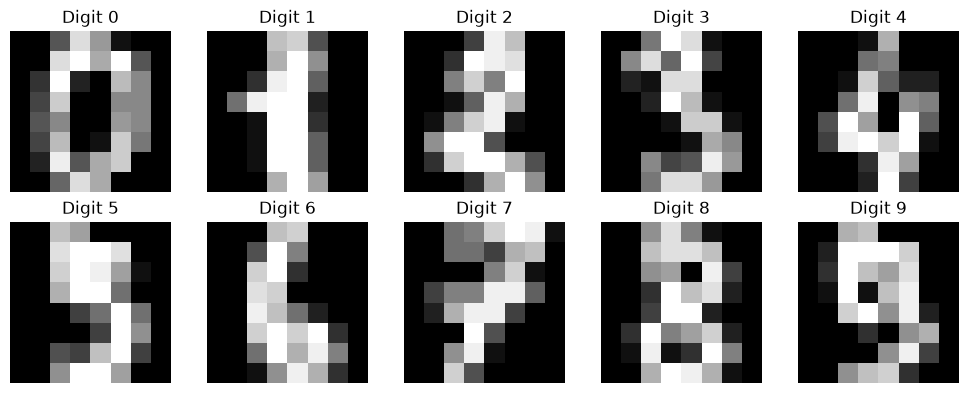

In [3]:
img_side = int(np.sqrt(X.shape[1]))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit in range(10):
    idx = np.where(y == digit)[0][0]
    img = X[idx].reshape(img_side, img_side)
    ax = axes[digit // 5, digit % 5]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. Preprocess and split

- Scale pixel values to [0, 1]
- Split into train/test (stratified to keep class balance)


In [4]:
# Scale pixels to [0, 1]
X = X / X.max()

# Stratified train/test split; use a fixed count for MNIST, a proportion otherwise
n_test = 10000 if USE_MNIST and len(y) >= 20000 else 0.2
n_train = 60000 if USE_MNIST and len(y) >= 70000 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=n_test,
    train_size=n_train,
    random_state=42,
    stratify=y,
)

print(f"Train: {X_train.shape}, {y_train.shape}")
print(f"Test:  {X_test.shape},  {y_test.shape}")


Train: (1437, 64), (1437,)
Test:  (360, 64),  (360,)


## 4. Train and compare classifiers

We train four supervised models and compare test-set accuracy.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=None, random_state=42
    ),
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name:18s}  test accuracy = {acc:.4f}")


Logistic Regression  test accuracy = 0.9556
k-NN (k=5)          test accuracy = 0.9833
SVM (RBF)           test accuracy = 0.9917
Random Forest       test accuracy = 0.9639


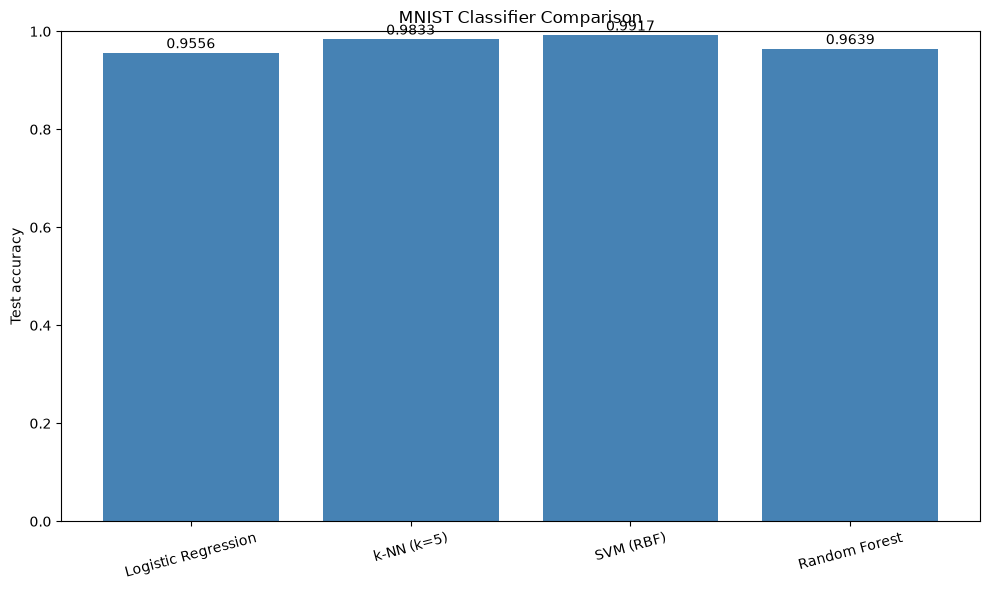

In [6]:
names = list(results.keys())
accs = list(results.values())

plt.bar(names, accs, color="steelblue")
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("MNIST Classifier Comparison")
plt.xticks(rotation=15)
for i, v in enumerate(accs):
    plt.text(i, v + 0.01, f"{v:.4f}", ha="center")
plt.tight_layout()
plt.show()


## 5. Detailed evaluation of the best model

In [7]:
best_name = max(results, key=results.get)
best_model = models[best_name]
y_pred = best_model.predict(X_test)

print(f"Best model: {best_name} (accuracy = {results[best_name]:.4f})\n")
print(classification_report(y_test, y_pred, digits=4))


Best model: SVM (RBF) (accuracy = 0.9917)

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9474    1.0000    0.9730        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     1.0000    1.0000    1.0000        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    1.0000    1.0000        36
           7     0.9730    1.0000    0.9863        36
           8     1.0000    0.9429    0.9706        35
           9     1.0000    0.9722    0.9859        36

    accuracy                         0.9917       360
   macro avg     0.9920    0.9915    0.9916       360
weighted avg     0.9920    0.9917    0.9917       360



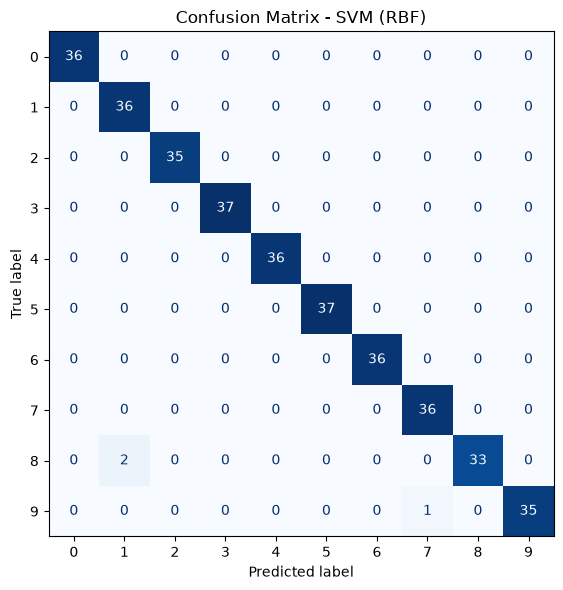

In [8]:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap="Blues",
    colorbar=False,
)
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()


## 6. Inspect misclassified digits

Misclassified: 3 / 360 test samples


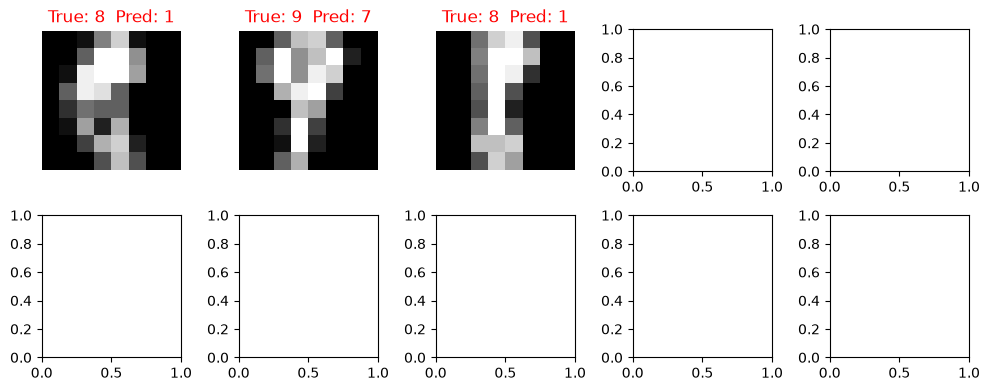

In [9]:
wrong = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(wrong)} / {len(y_test)} test samples")

n_show = min(10, len(wrong))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, idx in enumerate(wrong[:n_show]):
    img = X_test[idx].reshape(img_side, img_side)
    ax = axes[i // 5, i % 5]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"True: {y_test[idx]}  Pred: {y_pred[idx]}", color="red")
    ax.axis("off")
plt.tight_layout()
plt.show()


## Key takeaways

- MNIST is a classic supervised-learning benchmark: images (features) → digit labels (targets).
- Scaling pixel values to [0, 1] is essential for distance-based and gradient-based models.
- Tree models (Random Forest) and SVM typically outperform Logistic Regression and k-NN on MNIST raw pixels.
- Confusion matrices reveal which digit pairs are most confused (e.g., 4 vs 9, 3 vs 8).
- For higher accuracy, use CNNs (PyTorch/TensorFlow) or PCA + classifier pipelines.
